In [1]:
import pandas as pd    #dataframe
import numpy as np     #numerical data
import matplotlib.pyplot as plt    #makes graphs

from sklearn.model_selection import train_test_split    #splits data into training and testing
from sklearn.preprocessing import StandardScaler    #scales features on similar range

from sklearn.svm import SVC    #import libraries for support vector machines
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree    #import libraries for decision trees

from sklearn.metrics import accuracy_score    #import library for measuring model accuracy

In [2]:
columns = [
    'id', 'diagnosis',
    'radius_mean', 'texture_mean', 'perimeter_mean',
    'area_mean', 'smoothness_mean', 'compactness_mean',
    'concavity_mean', 'concave_points_mean',
    'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se',
    'area_se', 'smoothness_se', 'compactness_se',
    'concavity_se', 'concave_points_se',
    'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst',
    'area_worst', 'smoothness_worst', 'compactness_worst',
    'concavity_worst', 'concave_points_worst',
    'symmetry_worst', 'fractal_dimension_worst'
]

In [3]:
df = pd.read_csv('wdbc.data', header=None, names=columns)   #load the dataset into a pandas dataframe

df.head()   #display first five rows

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [5]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [6]:
df.shape

(569, 32)

In [7]:
df['diagnosis'].value_counts()

diagnosis
B    357
M    212
Name: count, dtype: int64

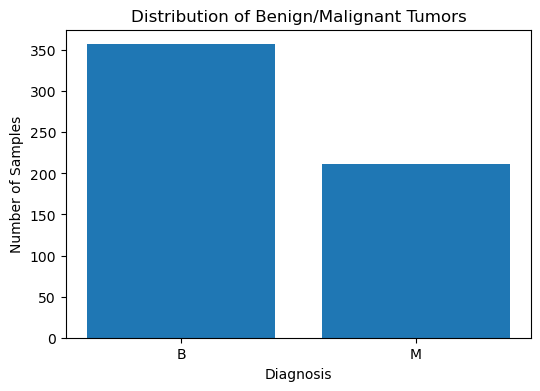

In [8]:
diagnosis_counts = df['diagnosis'].value_counts()   #counts number of samples in each diagnosis category


plt.figure(figsize=(6, 4))   #creates bar graph
plt.bar(diagnosis_counts.index, diagnosis_counts.values)


plt.xlabel('Diagnosis')   #graph labels
plt.ylabel('Number of Samples')
plt.title('Distribution of Benign/Malignant Tumors')

plt.show()   #shows graph

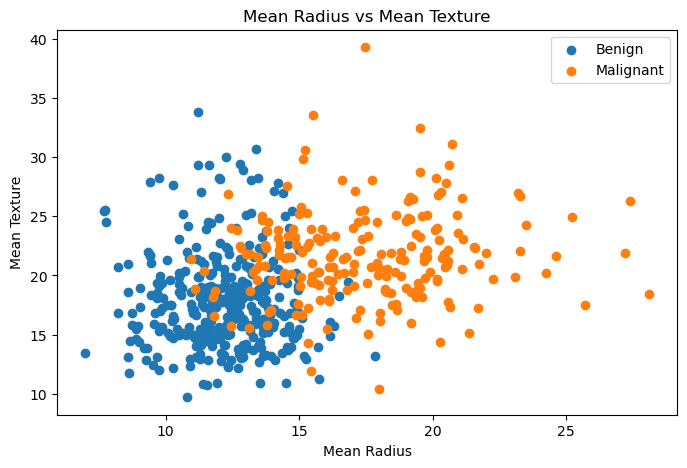

In [9]:
benign = df[df['diagnosis'] == 'B']   #separates benign and malignant samples
malignant = df[df['diagnosis'] == 'M']


plt.figure(figsize=(8, 5))   #figure size

plt.scatter(benign['radius_mean'], benign['texture_mean'], label='Benign')   #makes a scatter plot
plt.scatter(malignant['radius_mean'], malignant['texture_mean'], label='Malignant')


plt.xlabel('Mean Radius')   #graph labels
plt.ylabel('Mean Texture')
plt.title('Mean Radius vs Mean Texture')


plt.legend()   #shows legend and graph
plt.show()

In [10]:
#separates features and targets

X = df.drop(['id', 'diagnosis'], axis=1)    #features for predictions
y = df['diagnosis']    #prediction target

In [11]:
scaler = StandardScaler()   #scale features with StandardScaler
X_scaled = scaler.fit_transform(X)

In [12]:
#splits dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y   #0.2 = 20% for testing,42 = keeps split consistent 
)

In [13]:
scaler = StandardScaler()   #scales training and testing features

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
#prints size of training and testing data

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (455, 30)
Testing features: (114, 30)
Training target: (455,)
Testing target: (114,)


In [20]:
svm_linear = SVC(kernel='linear')
svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)
linear_accuracy = accuracy_score(y_test, y_pred_linear)

print("Linear SVM Accuaracy:", linear_accuracy)

Linear SVM Accuaracy: 0.9649122807017544


In [21]:
svm_kernel = SVC(kernel='rbf')
svm_kernel.fit(X_train_scaled, y_train)

y_pred_kernel = svm_kernel.predict(X_test_scaled)
kernel_accuracy = accuracy_score(y_test, y_pred_kernel)

print("Kernel SVM Accuarcy:", kernel_accuracy)

Kernel SVM Accuarcy: 0.9736842105263158


In [22]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)
tree_accuracy = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.9298245614035088


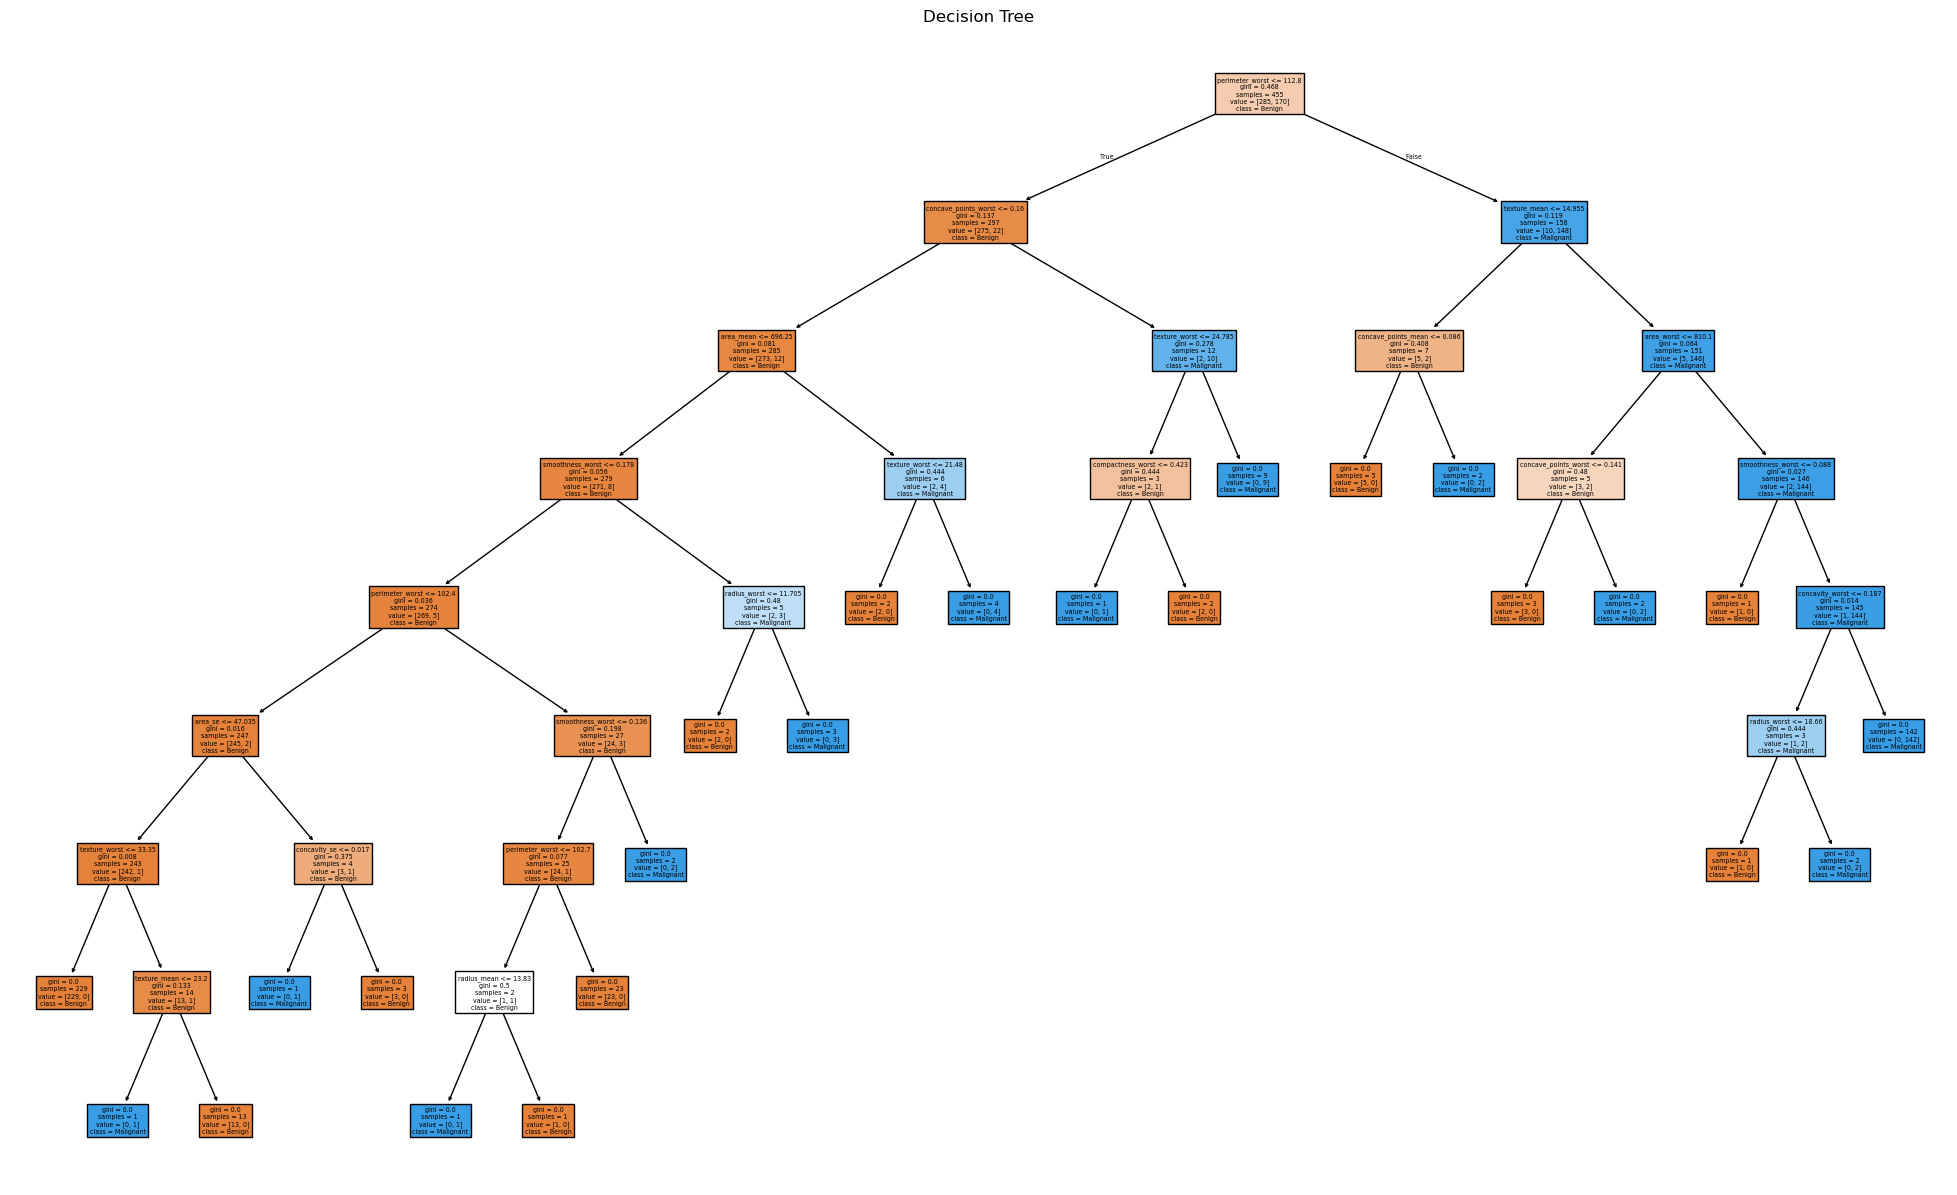

In [23]:
plt.figure(figsize=(25,15))

plot_tree(tree, feature_names=X.columns, class_names=['Benign', 'Malignant'], filled=True)

plt.title('Decision Tree')
plt.show()

In [24]:
print("Linear SVM Accuracy:", linear_accuracy)
print("Kernel SVM Accuracy:", kernel_accuracy)
print("Decision Tree Accuracy:", tree_accuracy)

Linear SVM Accuracy: 0.9649122807017544
Kernel SVM Accuracy: 0.9736842105263158
Decision Tree Accuracy: 0.9298245614035088
